# Problema 2: CN es de orden 3 local y 2 global

$N' = -\lambda N$, $\lambda = 1$, $N_0 = 100$, $T = 1$.  Con CN, $N_{n+1} = R_{\mathrm{CN}}(-\lambda h)\,N_n$ y

$$R_{\mathrm{CN}}(z) = \frac{1 + z/2}{1 - z/2}, \qquad R_{\mathrm{CN}}(-\lambda h) = \frac{2 - \lambda h}{2 + \lambda h}.$$

Este notebook calcula las tablas de los incisos (b) y (c), hace la gráfica log–log del inciso (d)
y la guarda en `figuras/p02_loglog.pdf`.

In [1]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

plt.rcParams.update({"figure.dpi": 110})

lam, N0, T = 1.0, 100.0, 1.0

def R_CN(z):
    return (1 + z / 2) / (1 - z / 2)

## Inciso (a): comprobación de la serie con SymPy

In [2]:
import sympy as sp
z = sp.symbols("z")
sp.series(sp.exp(z) - (1 + z/2) / (1 - z/2), z, 0, 6)

-z**3/12 - z**4/12 - 13*z**5/240 + O(z**6)

## Inciso (b): error local

Un solo paso desde $t = 0$ (con $N_0 = 100$): $e_{\mathrm{loc}}(h) = |e^{-\lambda h} - R_{\mathrm{CN}}(-\lambda h)|$.

In [3]:
h_loc = np.array([0.40, 0.20, 0.10, 0.05])
R_loc = R_CN(-lam * h_loc)
e_loc = np.abs(np.exp(-lam * h_loc) - R_loc)

rconv_loc = np.r_[np.nan, e_loc[:-1] / e_loc[1:]]
p_loc = np.log(rconv_loc) / np.log(2)

tab_loc = pd.DataFrame({"h": h_loc, "R_CN": R_loc, "e^{-h}": np.exp(-lam * h_loc),
                        "e_loc": e_loc, "h^3/12": h_loc**3 / 12,
                        "e_loc(2h)/e_loc(h)": rconv_loc, "p_loc": p_loc})
tab_loc.style.format({"h": "{:.2f}", "R_CN": "{:.12f}", "e^{-h}": "{:.12f}", "e_loc": "{:.6e}",
                      "h^3/12": "{:.6e}", "e_loc(2h)/e_loc(h)": "{:.6f}", "p_loc": "{:.6f}"}, na_rep="---").hide(axis="index")

h,R_CN,e^{-h},e_loc,h^3/12,e_loc(2h)/e_loc(h),p_loc
0.40,0.666666666667,0.670320046036,3.653379e-03,5.333333e-03,---,---
0.20,0.818181818182,0.818730753078,5.489349e-04,6.666667e-04,6.655396,2.734525
0.10,0.904761904762,0.904837418036,7.551327e-05,8.333333e-05,7.269383,2.861833
0.05,0.951219512195,0.951229424501,9.912306e-06,1.041667e-05,7.618134,2.929438


## Inciso (c): error global en $T = 1$

$n = T/h$ pasos: $N_n = R^n N_0$. Con $N_0 = 100$ la exacta en $T = 1$ es $100\,e^{-1}$, así que $E(h) = |N_{T/h} - 100\,e^{-1}|$.

In [4]:
h_glo = np.array([1/2, 1/4, 1/8, 1/16])
n_glo = np.rint(T / h_glo).astype(int)
R_glo = R_CN(-lam * h_glo)
Nn = N0 * R_glo**n_glo                      # N_{T/h} con N_0 = 100
E = np.abs(Nn - N0 * np.exp(-lam * T))     # con N_0 = 100: exacta 100 e^{-1}

rconv_glo = np.r_[np.nan, E[:-1] / E[1:]]
p_glo = np.log(rconv_glo) / np.log(2)

tab_glo = pd.DataFrame({"h": ["1/2", "1/4", "1/8", "1/16"], "n": n_glo, "R_CN": R_glo,
                        "N_n (N0=100)": Nn, "E(h)": E, "100 e^{-1} h^2/12": N0 * np.exp(-1) * h_glo**2 / 12,
                        "E(2h)/E(h)": rconv_glo, "p_glob": p_glo})
tab_glo.style.format({"R_CN": "{:.12f}", "N_n (N0=100)": "{:.7f}", "E(h)": "{:.6e}",
                      "100 e^{-1} h^2/12": "{:.6e}", "E(2h)/E(h)": "{:.6f}", "p_glob": "{:.6f}"}, na_rep="---").hide(axis="index")

h,n,R_CN,N_n (N0=100),E(h),100 e^{-1} h^2/12,E(2h)/E(h),p_glob
1/2,2,0.600000000000,36.0000000,7.879441e-01,7.664155e-01,---,---
1/4,4,0.777777777778,36.5950312,1.929129e-01,1.916039e-01,4.084456,2.030144
1/8,8,0.882352941176,36.7399619,4.798223e-02,4.790097e-02,4.020506,2.007377
1/16,16,0.939393939394,36.7759638,1.198031e-02,1.197524e-02,4.005090,2.001835


## Inciso (d): gráfica log–log

Las líneas punteadas son las predicciones teóricas: $h^3/12$ (pendiente 3, inciso a) y $100\,e^{-1}h^2/12$ (pendiente 2, inciso d).

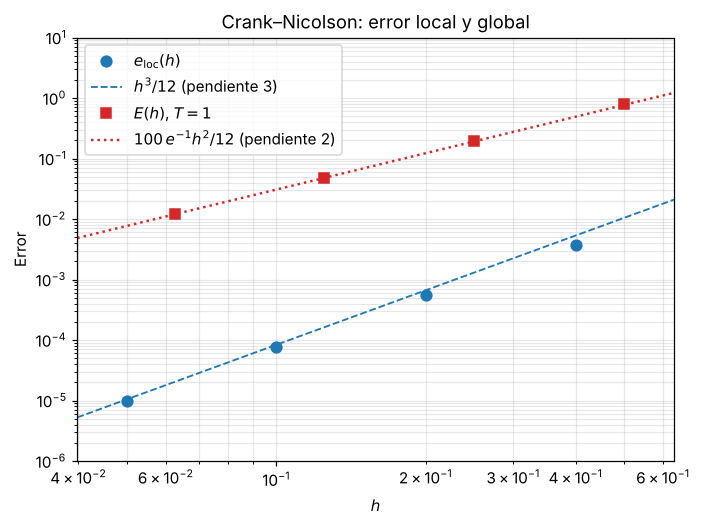

In [5]:
hh = np.logspace(-1.4, -0.2, 100)

fig, ax = plt.subplots(figsize=(7, 5))
ax.loglog(h_loc, e_loc, "o", ms=7, color="C0", label=r"$e_{\mathrm{loc}}(h)$")
ax.loglog(hh, hh**3 / 12, "--", color="C0", lw=1.2, label=r"$h^3/12$ (pendiente 3)")
ax.loglog(h_glo, E, "s", ms=7, color="C3", label=r"$E(h)$, $T = 1$")
ax.loglog(hh, N0 * np.exp(-1) * hh**2 / 12, ":", color="C3", lw=1.6, label=r"$100\,e^{-1}h^2/12$ (pendiente 2)")

ax.set_xlim(10**-1.4, 10**-0.2)
ax.set_ylim(1e-6, 1e1)
ax.set_xlabel(r"$h$")
ax.set_ylabel("Error")
ax.set_title("Crank–Nicolson: error local y global")
ax.grid(True, which="both", alpha=0.3)
ax.legend(loc="upper left")

os.makedirs("figuras", exist_ok=True)
fig.savefig("figuras/p02_loglog.pdf", bbox_inches="tight")
fig.savefig("figuras/p02_loglog.png", dpi=200, bbox_inches="tight")
plt.show()

## Pendientes: entre los extremos, entre los dos últimos puntos y por mínimos cuadrados

In [6]:
def pendientes(h, e):
    x, y = np.log10(h), np.log10(e)
    extremos = (y[-1] - y[0]) / (x[-1] - x[0])
    ultimos = (y[-1] - y[-2]) / (x[-1] - x[-2])
    mc = np.polyfit(x, y, 1)[0]
    return extremos, ultimos, mc

for nombre, h, e in [("local", h_loc, e_loc), ("global", h_glo, E)]:
    a, b, c = pendientes(h, e)
    print(f"{nombre:6s}  extremos = {a:.6f}   dos últimos = {b:.6f}   mínimos cuadrados = {c:.6f}")

local   extremos = 2.841932   dos últimos = 2.929438   mínimos cuadrados = 2.843922
global  extremos = 2.013119   dos últimos = 2.001835   mínimos cuadrados = 2.012544


## Cota y estimación del error global

$|E| \le \dfrac{\lambda^3 T N_0}{12}h^2$ (con $N_0 = 100$) y $E \approx \dfrac{\lambda^3 T}{12}h^2\,N_0 e^{-\lambda T}$.

In [7]:
for h, e in zip(h_glo, E):
    print(f"h = 1/{round(1/h):2d}   E = {e:.6e}   estimación = {N0*np.exp(-1)*h**2/12:.6e}   cota = {N0*h**2/12:.6e}")

h = 1/ 2   E = 7.879441e-01   estimación = 7.664155e-01   cota = 2.083333e+00
h = 1/ 4   E = 1.929129e-01   estimación = 1.916039e-01   cota = 5.208333e-01
h = 1/ 8   E = 4.798223e-02   estimación = 4.790097e-02   cota = 1.302083e-01
h = 1/16   E = 1.198031e-02   estimación = 1.197524e-02   cota = 3.255208e-02
